# Monte Carlo: a smarter search for low-energy configurations

In `02_random_sampling_walkthrough.ipynb`, we searched for low-energy configurations by random sampling. Random sampling is simple and easy to run in parallel, but it has two limitations:

- Most configurations have middling energies, so random sampling only rarely finds the low-energy ones. Finding the most stable configurations takes a very large number of samples.
- Every sampled configuration keeps each sublattice's occupancy fixed at its value in the parent, so we need to know those occupancies in advance. For example, if the parent LLZO structure has 54.2% Li occupancy on the tetrahedral sites and 89.6% on the octahedral sites, every sampled configuration has exactly those occupancies.

*Monte Carlo* (MC) takes a different approach. It starts from one configuration and makes a long series of small changes, always keeping changes that lower the energy and occasionally keeping ones that raise it. Each step builds on the last, so the simulation can work its way down toward low-energy configurations instead of starting over each time. MC can also let the occupancies change. With moves that hop ions from one sublattice to another (for example, Li from tetrahedral to octahedral sites), the simulation finds how the ions distribute across sublattices instead of having that fixed in advance (see `cli_example/monte_carlo`). The swap moves used in this notebook keep the occupancies fixed, just as random sampling does.

This notebook explains how MC works, runs it on the same LTO supercell, and compares it with random sampling. It saves the run for `04_MC_analysis.ipynb`, which looks at the results in more detail.

## How Monte Carlo works

Each MC step does three things:

1. **Propose a move.** Make a small change to the current configuration. Here, that means swapping a Li and a Ti on the mixed sites.
2. **Calculate the energy change**, $\Delta E = E_\text{new} - E_\text{current}$.
3. **Accept or reject the move** using the *Metropolis rule*:
   - if $\Delta E \le 0$ (the energy goes down), always accept;
   - if $\Delta E > 0$ (the energy goes up), accept with probability $e^{-\Delta E / k_B T}$.

   If the move is rejected, the simulation stays on the current configuration for this step.

The temperature $T$ controls how often uphill moves are accepted. At low temperature almost every uphill move is rejected, so the simulation heads straight downhill and can get stuck in the first low-energy configuration it finds (a *local minimum*). At high temperature more uphill moves are accepted, so the simulation can climb out of local minima and explore, but it spends less of its time at low energies. At very high $T$ almost every move is accepted, and MC behaves much like random sampling, except that each configuration differs only slightly from the one before.

<details>
<summary>Why the Metropolis rule?</summary>

At thermal equilibrium, statistical mechanics says a system is found in configuration $i$ with probability proportional to its Boltzmann factor, $P_i \propto e^{-E_i / k_B T}$. The Metropolis rule is chosen so that, after enough steps, the simulation visits configurations with exactly these probabilities.

The key property is *detailed balance*: for any two configurations $a$ and $b$, the rate of moving $a \to b$ equals the rate of moving $b \to a$ at equilibrium,

$$P_a \, W(a \to b) = P_b \, W(b \to a).$$

If $E_b > E_a$, the move $a \to b$ is accepted with probability $e^{-(E_b - E_a)/k_B T}$ and the reverse move always is. Their ratio is $e^{-(E_b - E_a)/k_B T} = P_b / P_a$, which is exactly what detailed balance requires. This also needs the move $a \to b$ to be proposed as often as $b \to a$, which is true for the swaps used here.

When detailed balance holds, MC is more than a search method: averages over a long run are thermal averages at temperature $T$. This is how MC is used to calculate properties such as the amount of short-range order at a given temperature (see `demos/li4ti5o12_short_range_order`).

You can also write MC policies that break detailed balance, which can be a more efficient way to search for low-energy structures. Averages over such a run are not correct thermal averages, though the configurations and energies it finds are still valid. A policy like this should set `MonteCarloPolicy.detailed_balance = False`, so that `run_monte_carlo` warns (with a `DetailedBalanceWarning`) that the trajectory averages are biased.

</details>

In [1]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pymatgen.core import Structure

from disorderly import (
    KB_EV_PER_K,
    PrecomputedEwald,
    propose_next_configuration,
    random_energy_sampling,
    random_ordered_configuration,
    run_monte_carlo,
    save_structures,
    save_trajectory,
    sublattice_swap_policy,
)

structures_dir = Path("../tests/test_structures")
output_dir = Path("mc_example_out") # Files written by this notebook go here; 04_MC_analysis.ipynb reads them

## 1. Set up the structure and a starting configuration

We use the same parent as in the random sampling notebook: a 2×2×3 supercell of LTO's primitive cell, with 8 Li and 40 Ti on its 48 mixed sites.

MC needs an ordered configuration to start from. Any valid configuration works, so we pick a random one.

In [2]:
lto = Structure.from_file(structures_dir / "LTO_COD_1001098.cif")
parent = lto.get_primitive_structure() # The smallest cell that repeats to build the crystal: 14 sites
parent.make_supercell([2, 2, 3]) # 2 x 2 x 3 copies of it: 168 sites

initial = random_ordered_configuration(parent, np.random.default_rng(0))
print(f"starting configuration: {initial.composition.formula}, {len(initial)} sites")

starting configuration: Li32 Ti40 O96, 168 sites


## 2. Choose the moves and the energy model

The package calls the rules of an MC simulation a *policy*. A policy has three parts:

- `choose_potential_move`: which move to try next;
- `is_move_allowed`: whether a proposed move is allowed (by default, the composition must not change);
- `evaluate_props`: the energy of a configuration, plus any other properties you want recorded.

`sublattice_swap_policy` builds a policy whose moves swap the species on two sites of the same disordered sublattice. Here, that means swapping a Li and a Ti on the mixed sites. The other Li and the O never move. For the energy we use the same `PrecomputedEwald` model as in random sampling.

`default_policy` is also available, but it swaps any two different species anywhere in the cell, including O with Ti. Almost all of those moves would be rejected, so it is a poor choice here.

In [3]:
ewald = PrecomputedEwald(parent)
policy = sublattice_swap_policy(parent, evaluate_props=ewald.evaluate_props) # Swap Li and Ti on the mixed sites, score with Ewald

## 3. One step by hand

Before running thousands of steps, let's take one ourselves. `propose_next_configuration` asks the policy for a move, builds the new configuration, and calculates its energy:

In [4]:
candidate, move, properties = propose_next_configuration(initial, policy, np.random.default_rng(6))

current_energy = ewald(initial)
delta_e = properties["energy"] - current_energy
print(f"proposed move: swap the {initial[move.site_index].species_string} on site {move.site_index} "
      f"with the {initial[move.target_site_index].species_string} on site {move.target_site_index}")
print(f"energy change: {delta_e:+.2f} eV")

proposed move: swap the Ti4+ on site 141 with the Li+ on site 124
energy change: +6.62 eV


This move raises the energy, so the Metropolis rule accepts it only with probability $e^{-\Delta E / k_B T}$. Here is that probability at a few temperatures:

In [5]:
for temperature in [300, 3000, 10000, 30000]:
    kT = KB_EV_PER_K * temperature # Thermal energy in eV
    probability = min(1.0, np.exp(-delta_e / kT))
    print(f"T = {temperature:>6,} K:  kT = {kT:.3f} eV,  acceptance probability {probability:.2g}")

T =    300 K:  kT = 0.026 eV,  acceptance probability 6.7e-112
T =  3,000 K:  kT = 0.259 eV,  acceptance probability 7.6e-12
T = 10,000 K:  kT = 0.862 eV,  acceptance probability 0.00046
T = 30,000 K:  kT = 2.585 eV,  acceptance probability 0.077


At room temperature this move would essentially never be accepted. That comes from the energy model, not the physics. The Ewald energy treats ions as bare point charges, which greatly exaggerates the energy differences between configurations: a single Li/Ti swap changes the energy by several eV. So to explore configurations with Ewald energies, we run MC at around 10,000 K. Think of this temperature as a knob that controls how much the simulation explores, not as a real temperature.

More realistic energy models, such as machine-learned interatomic potentials (MLIPs) or DFT, give much smaller energy differences, so they work at realistic temperatures.

## 4. Run the simulation

`run_monte_carlo` repeats the propose / evaluate / accept-or-reject step `num_steps` times. We use 2,000 steps, the same number of energy calculations as the random sampling run in the previous notebook.

In [6]:
temperature = 10000 # In kelvin
num_steps = 2000

trajectory = run_monte_carlo(
    initial,
    policy,
    temperature=temperature,
    num_steps=num_steps, # Number of moves to propose
    num_structures_to_save=10, # Keep the 10 lowest-energy configurations seen during the run
    seed=0, # Fixes the random numbers, so rerunning gives the same result
    record_structure_every=500, # Also store the current configuration every 500 steps
)

energies = np.array(trajectory.energies) # Energy of the current configuration after each step
print(f"starting energy:         {energies[0]:.2f} eV")
print(f"final energy:            {energies[-1]:.2f} eV")
print(f"lowest energy seen:      {trajectory.lowest_energy_saved()[0].energy:.2f} eV")
print(f"fraction of moves accepted: {trajectory.acceptance_rate():.3f}")

starting energy:         -5993.81 eV
final energy:            -6026.10 eV
lowest energy seen:      -6026.72 eV
fraction of moves accepted: 0.025


The returned `trajectory` records every step: the energy of the current configuration, the proposed move, and whether it was accepted. It also keeps the `num_structures_to_save` lowest-energy configurations seen. These include configurations from moves that were *rejected*, since a low-energy configuration is worth keeping even if the simulation didn't move to it.

Only a small fraction of moves were accepted, which is typical with the large Ewald energy differences. `04_MC_analysis.ipynb` looks at the acceptance rate and the effect of temperature in more detail.

## 5. Compare with random sampling

Let's run random sampling with the same number of energy calculations and compare:

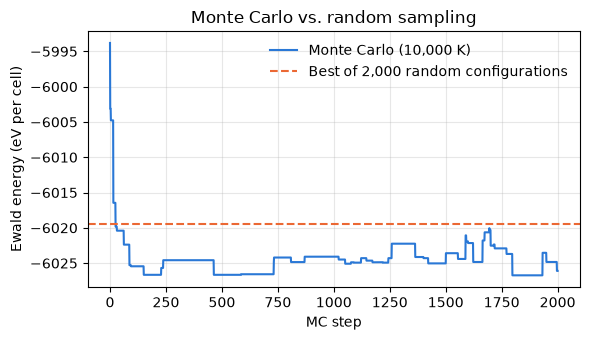

best from random sampling: -6019.48 eV
best from Monte Carlo:     -6026.72 eV


In [7]:
random_best = random_energy_sampling(parent, ewald, n_attempts=num_steps, n_return=1, seed=0, verbose=False)[0]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(energies, color="#2a78d6", linewidth=1.5, label=f"Monte Carlo ({temperature:,} K)")
ax.axhline(random_best.energy, color="#eb6834", linewidth=1.5, linestyle="--", label=f"Best of {num_steps:,} random configurations")
ax.set_xlabel("MC step")
ax.set_ylabel("Ewald energy (eV per cell)")
ax.set_title("Monte Carlo vs. random sampling")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"best from random sampling: {random_best.energy:.2f} eV")
print(f"best from Monte Carlo:     {trajectory.lowest_energy_saved()[0].energy:.2f} eV")

The MC energy drops quickly from its random starting point. It passes the best configuration random sampling found and then fluctuates at lower energies. With the same number of energy calculations, MC finds lower-energy configurations, because each step builds on a configuration that is already good.

## 6. Save the results

`save_trajectory` writes the whole trajectory to a JSON file, and `save_structures` writes the lowest-energy configurations as CIF files. `04_MC_analysis.ipynb` loads this trajectory.

In [8]:
output_dir.mkdir(exist_ok=True)
trajectory_path = save_trajectory(trajectory, output_dir / "trajectory.json")
cif_paths = save_structures([config.structure for config in trajectory.lowest_energy_saved()], output_dir / "lowest_energy", prefix="mc")
print(f"saved {trajectory_path} and {len(cif_paths)} CIF files in {cif_paths[0].parent}")

saved mc_example_out/trajectory.json and 10 CIF files in mc_example_out/lowest_energy


## Going further

**Command line.** For long runs, the `run-monte-carlo` command runs the same simulation without a notebook:

```bash
run-monte-carlo parent.cif initial.cif 10000 settings.py
```

Its arguments are the parent structure, a starting configuration, the temperature, and a Python settings file. The settings file defines the policy (as `policy = ...` or with a `get_policy(...)` function), plus options like `num_steps` and `seed`. `src/disorderly/cli/monte_carlo_settings_reference.py` lists every option. Long runs can also save *checkpoints* as they go and pick up where they left off with `resume_monte_carlo`, which is useful on clusters with time limits.

**More realistic energies.** `mace_policy` and `chgnet_policy` build swap policies scored by machine-learned potentials instead of Ewald (optional extras, as in the random sampling notebook). With these, energy differences are realistic, and so are temperatures.

**Vacancies.** The swap moves used here only exchange two atoms, so they work when every site in the configuration is occupied, as in LTO. A structure like LLZO, where Li sites can be empty, also needs moves that hop an atom onto an empty site. Those need a custom `choose_potential_move` that proposes `"move"`-type moves; see `disorderly.settings` for the policy interface.

## Summary

- MC makes a series of small moves, accepting or rejecting each with the Metropolis rule. Downhill moves are always accepted, and uphill moves are accepted with probability $e^{-\Delta E / k_B T}$.
- A *policy* sets the allowed moves and the energy model. `sublattice_swap_policy` swaps species within a disordered sublattice.
- Temperature controls the balance between exploring and settling into low energies. With Ewald energies, very high temperatures are needed, because the energy differences are exaggerated.
- For the same number of energy calculations, MC found lower-energy configurations than random sampling.

Next, `04_MC_analysis.ipynb` loads this run and looks at it in more detail: how the energy and acceptance rate change over the run, what temperature does, and which distinct structures were found.